In [250]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
RAW = ROOT / "data" / "processed" / "clean.csv"
df = pd.read_csv(RAW)

In [251]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [252]:
df.describe()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,650.528800,0.545700,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,96.653299,0.497932,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,350.000000,0.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,584.000000,0.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,652.000000,1.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,718.000000,1.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,850.000000,1.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [253]:
df.groupby("Exited")[["Age", "IsActiveMember", "Balance"]].mean()

,Age,IsActiveMember,Balance
Exited,,,
0,37.408389,0.554565,72745.296779
1,44.837997,0.360825,91108.539337


In [254]:
df.groupby(pd.cut(df["CreditScore"], bins=5))["Exited"].agg(["mean", "size"])


,mean,size
CreditScore,,
"(349.5, 450.0]",0.322751,189
"(450.0, 550.0]",0.214385,1432
"(550.0, 650.0]",0.207780,3316
"(650.0, 750.0]",0.192496,3465
"(750.0, 850.0]",0.195870,1598


In [255]:
df.groupby(pd.cut(df["EstimatedSalary"], bins=5))["Exited"].agg(["mean", "size"])


,mean,size
EstimatedSalary,,
"(-188.401, 40007.76]",0.201535,1955
"(40007.76, 80003.94]",0.198229,2033
"(80003.94, 120000.12]",0.200591,2029
"(120000.12, 159996.3]",0.202112,1989
"(159996.3, 199992.48]",0.216148,1994


In [256]:
df.groupby("Tenure")["Exited"].mean()

Tenure
0     0.230024
1     0.224155
2     0.191794
3     0.211100
4     0.205258
5     0.206522
6     0.202689
7     0.172179
8     0.192195
9     0.216463
10    0.206122
Name: Exited, dtype: float64

In [257]:
print("sum of customers with zero balance",(df['Balance'] == 0).sum())


print("mean",(df['Balance'] == 0).mean())


sum of customers with zero balance 3617
mean 0.3617


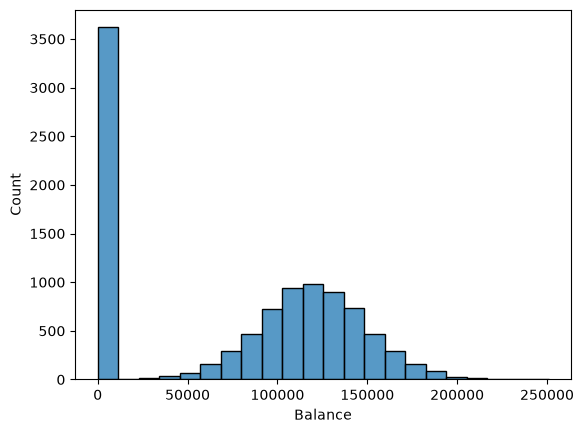

In [258]:
sns.histplot(df['Balance'])

plt.show()

In [259]:
df.groupby(pd.cut(df['Age'], bins=[17,25,35,45,55,65,75,95]))["Exited"].mean()

Age
(17, 25]    0.075286
(25, 35]    0.084980
(35, 45]    0.196199
(45, 55]    0.505721
(55, 65]    0.483209
(65, 75]    0.155251
(75, 95]    0.022222
Name: Exited, dtype: float64

In [260]:

df.groupby("NumOfProducts")["Exited"].agg(["mean", "size"])

,mean,size
NumOfProducts,,
1,0.277144,5084
2,0.075817,4590
3,0.827068,266
4,1.000000,60


In [261]:
df.groupby('HasCrCard')['Exited'].mean()

HasCrCard
0    0.208149
1    0.201843
Name: Exited, dtype: float64

In [262]:
df.groupby('IsActiveMember')['Exited'].mean()

IsActiveMember
0    0.268509
1    0.142691
Name: Exited, dtype: float64

In [263]:
df.groupby("Geography")["Exited"].agg(["mean", "size"])

,mean,size
Geography,,
France,0.161548,5014
Germany,0.324432,2509
Spain,0.166734,2477


In [264]:
df.groupby("Gender")["Exited"].agg(["mean", "size"])

,mean,size
Gender,,
0,0.250715,4543
1,0.164559,5457


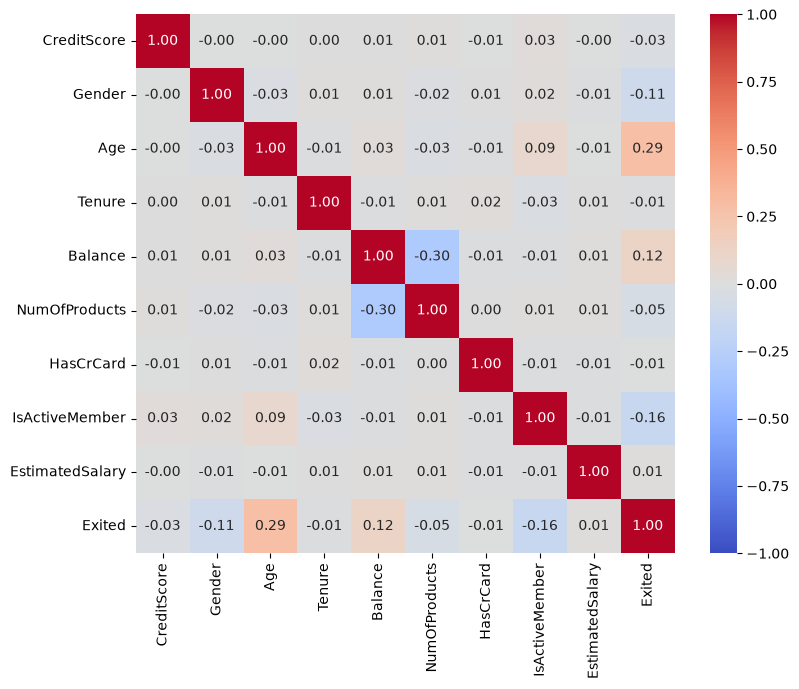

In [265]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
plt.show()

## Bank Churn: EDA, Feature Engineering and Modelling Plan

About 20% of customers left the bank. Age, number of products, activity status, country, gender and account balance showed differences in churn rates, while credit card ownership, salary, tenure and credit score are mostly flat,apart from a small low-score group that churns more

Feature engineering will include creating age groups, treating the number of products as categories, one-hot encoding country, and adding a flag to show whether a customer has a balance. A plain logistic regression comes first, and these features only stay if they improve it in cross-validation.

Logistic regression, decision trees and random forests will be compared using the same cross-validation method. The best model will be selected based on churn recall and precision, then evaluated once on an untouched test set.